In [1]:
%pip install -q numpy scipy matplotlib qiskit==2.3.1 qiskit-aer==0.17.2


[notice] A new release of pip is available: 24.2 -> 26.2.2
[notice] To update, run: python -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


In [2]:
import sys, os, json, time
sys.path.insert(0, os.path.abspath('..'))   # make `evqaoa` and `experiments` importable from notebooks/
import numpy as np
import matplotlib.pyplot as plt
from qiskit import transpile
from qiskit.quantum_info import Statevector
from evqaoa import charging_model, to_ising, qaoa_circuit
from experiments import scaling as sc

OUT = os.path.abspath('../results/03_scaling'); os.makedirs(OUT, exist_ok=True)
WEIGHTS = (0.5, 0.3, 0.2)                  # cost, peak load, switching weights (the project default)
SIZES = [(3, 4), (4, 4), (4, 5), (4, 6), (5, 5)]   # (vehicles, slots)
RESTARTS, MAXITER = 6, 300                  # budget caps to keep the notebook fast
SOURCE_RESTARTS, SOURCE_MAXITER = 12, 500   # more effort for the DEPOT 'source' angles
GATES = ['rz', 'sx', 'x', 'cx']
COL = {'transfer': '#0072B2', 'warm': '#E69F00', 'random': '#009E73', 'sim': '#CC79A7', 'qiskit': '#555555'}
T0 = time.time()

# 03 - System-size scaling and parameter transfer

**Why this notebook?** Our core study solves one small depot: 3 vehicles x 4 hourly slots = 12 qubits. The hackathon
brief asks about the *system size effect*: what happens to QAOA as the problem grows? We answer two questions.

1. **Larger depots** - 4x4 (16 qubits), 4x5 (20), 4x6 (24) and a 5x5 (25 qubits) stretch case.
2. **Parameter transfer** - QAOA has to *learn* its angles (beta, gamma) with a classical optimiser, and every
   evaluation is a circuit run. If angles learned on the cheap 12-qubit depot also work on bigger ones, we skip most of
   that cost. (Transfer of QAOA angles between related instances is discussed in e.g. Brandao et al. 2018,
   arXiv:1812.04170, and Galda et al. 2021, arXiv:2106.07531.)

**Workflow**
1. Define a family of problems (`ChargingProblem`, one qubit per vehicle-slot pair) with a night tariff in cents/kWh.
2. Simulate QAOA *exactly* with the XY mixer and the Dicke start. These never leave the schedules that meet every
   vehicle's demand, so we simulate only that feasible subspace (e.g. 50,625 states for 4x6 instead of 2^24 = 16.8
   million). We verify this fast simulator against Qiskit's `Statevector` (unit tests plus a check below).
3. Scaling study: solution quality, optimiser effort, simulation time and transpiled circuit size against qubit count.
4. Transfer study: (a) DEPOT angles used directly, (b) DEPOT angles as a warm start, (c) random-start optimisation.

*All metrics are over valid schedules only (the XY mixer keeps the valid rate at 100%). Approximation ratio =
(worst - mean) / (worst - best) energy over valid schedules, so 1 is perfect. Picking a valid schedule uniformly at
random already scores well above 0 (printed below as the 'uniform' baseline), and that is the bar QAOA must beat.*

## 1. The problem family
Prices follow a night time-of-use tariff in cents/kWh: an expensive evening peak, a cheap overnight trough, rising
again toward morning. The 4-slot tariff is the depot's (32, 14, 9, 21). The 5- and 6-slot tariffs are our own plausible
stretches of it, stepping down gradually into the same 9 c/kWh trough and ending at the same 21 c/kWh morning price:

* 5 slots: (32, 18, 11, 9, 21)
* 6 slots: (32, 20, 13, 9, 10, 21)

The depot keeps its own demand (2, 1, 2 slots); every other size gives each vehicle 2 slots. Brute force only has to
enumerate valid schedules (a product of binomials), so the exact best/worst energies stay cheap.

In [3]:
rows, setups = [], {}
for V, T in SIZES:
    problem = sc.make_problem(V, T)
    model = charging_model(problem, WEIGHTS)
    setups[(V, T)] = (problem, model)
    n_feas = len(sc.feasible_basis(problem))
    rows.append(dict(name=f'{V}x{T}', vehicles=V, slots=T, qubits=problem.n_qubits, tariff=list(problem.tariff),
                     demand=list(problem.demand), feasible=n_feas, full_space=2 ** problem.n_qubits))
print(f"{'size':>5} {'qubits':>6} {'valid':>9} {'2^n':>12}  tariff (c/kWh)    demand")
for r in rows:
    print(f"{r['name']:>5} {r['qubits']:>6} {r['feasible']:>9,} {r['full_space']:>12,}  {str(r['tariff']):<22}{r['demand']}")

 size qubits     valid          2^n  tariff (c/kWh)    demand
  3x4     12       144        4,096  [32, 14, 9, 21]       [2, 1, 2]
  4x4     16     1,296       65,536  [32, 14, 9, 21]       [2, 2, 2, 2]
  4x5     20    10,000    1,048,576  [32, 18, 11, 9, 21]   [2, 2, 2, 2]
  4x6     24    50,625   16,777,216  [32, 20, 13, 9, 10, 21][2, 2, 2, 2]
  5x5     25   100,000   33,554,432  [32, 18, 11, 9, 21]   [2, 2, 2, 2, 2]


## 2. Sanity check: fast simulator vs Qiskit

Before trusting the subspace simulator, compare it with Qiskit's full `Statevector` on the circuit from
`evqaoa.qaoa_circuit` (random p=2 angles on the depot). The difference should be at machine precision.

In [4]:
problem, model = setups[(3, 4)]
H = to_ising(model)
th = np.random.default_rng(5).uniform(0, np.pi, 4)
ref = Statevector(qaoa_circuit(problem, H, 2).assign_parameters(th)).expectation_value(H).real
fast = sc.make_simulator(problem, model).energy(th)
print(f'Qiskit Statevector: {ref:.12f}\nSubspace simulator: {fast:.12f}\n|difference| = {abs(ref-fast):.2e}')
assert abs(ref - fast) < 1e-9

Qiskit Statevector: 0.702629231813
Subspace simulator: 0.702629231813
|difference| = 3.89e-15


## 3. Scaling study (XY mixer + Dicke start, p = 1 and 2)

For each size and depth we run the optimiser from several random starts (COBYLA, capped budget) and record the
approximation ratio, P(optimal), the number of energy evaluations, and time per evaluation.

In [5]:
scaling = {}   # (size, p) -> dict
for (V, T) in SIZES:
    problem, model = setups[(V, T)]
    sim = sc.make_simulator(problem, model)
    for p in (1, 2):
        t_eval = sc.time_call(lambda: sim.energy(np.full(2 * p, 0.3)), repeats=5)
        run = sc.random_restarts(sim.energy, 2 * p, RESTARTS, MAXITER, seed=0)
        m = sc.metrics(sim, run['x'])
        scaling[(V, T, p)] = dict(size=f'{V}x{T}', qubits=problem.n_qubits, p=p, approx_ratio=m['approx_ratio'],
                                  p_optimal=m['p_optimal'], energy=m['energy'], e_best=m['e_best'],
                                  e_worst=m['e_worst'], e_mean_uniform=m['e_mean_uniform'],
                                  nfev=run['nfev'], sec_per_eval=t_eval, theta=run['x'].tolist(),
                                  ar_uniform=(m['e_worst']-m['e_mean_uniform'])/(m['e_worst']-m['e_best']),
                                  p_opt_uniform=float(np.isclose(sim.energies, m['e_best'], atol=1e-9).sum() / len(sim.energies)))
print(f"{'size':>5} {'q':>3} {'p':>2} {'approx':>7} {'AR unif.':>8} {'P(opt)':>8} {'P(opt) unif.':>12} {'evals':>6} {'ms/eval':>8}")
for k, r in scaling.items():
    print(f"{r['size']:>5} {r['qubits']:>3} {r['p']:>2} {r['approx_ratio']:>7.3f} {r['ar_uniform']:>8.3f} {r['p_optimal']:>8.4f} {r['p_opt_uniform']:>12.5f} {r['nfev']:>6} {1e3*r['sec_per_eval']:>8.2f}")

 size   q  p  approx AR unif.   P(opt) P(opt) unif.  evals  ms/eval
  3x4  12  1   0.744    0.663   0.0386      0.02778   1531     0.07
  3x4  12  2   0.810    0.663   0.1064      0.02778   1800     0.13
  4x4  16  1   0.691    0.674   0.0092      0.00926   1535     0.21
  4x4  16  2   0.844    0.674   0.1056      0.00926   1800     0.39
  4x5  20  1   0.698    0.680   0.0021      0.00120   1800     1.29
  4x5  20  2   0.746    0.680   0.0009      0.00120   1800     2.54
  4x6  24  1   0.672    0.661   0.0005      0.00047   1800     7.07
  4x6  24  2   0.779    0.661   0.0089      0.00047   1800    13.79
  5x5  25  1   0.707    0.695   0.0004      0.00030   1800    13.72
  5x5  25  2   0.757    0.695   0.0001      0.00030   1800    41.16


### Circuit size after transpiling

Transpiled to the generic basis `rz, sx, x, cx` (optimisation level 1). Two-qubit gates (`cx`) are what hurts on real hardware; this is the *all-to-all* count before any hardware routing, so real devices will need more.

In [6]:
circ_stats = {}
for (V, T) in SIZES:
    problem, model = setups[(V, T)]
    H = to_ising(model)
    for p in (1, 2):
        t0 = time.time()
        tq = transpile(qaoa_circuit(problem, H, p), basis_gates=GATES, optimization_level=1, seed_transpiler=0)
        circ_stats[(V, T, p)] = dict(size=f'{V}x{T}', qubits=problem.n_qubits, p=p, depth=tq.depth(),
                                     cx=int(tq.count_ops().get('cx', 0)), total_gates=int(sum(tq.count_ops().values())))
        print(f"{V}x{T} p={p}: depth {tq.depth():>5}, cx {circ_stats[(V,T,p)]['cx']:>5}  ({time.time()-t0:.1f}s to transpile)")

3x4 p=1: depth   107, cx    93  (0.7s to transpile)
3x4 p=2: depth   142, cx   153  (0.0s to transpile)
4x4 p=1: depth   115, cx   140  (0.0s to transpile)
4x4 p=2: depth   153, cx   236  (0.0s to transpile)
4x5 p=1: depth   161, cx   228  (0.0s to transpile)
4x5 p=2: depth   202, cx   352  (0.0s to transpile)
4x6 p=1: depth   302, cx   380  (0.1s to transpile)


4x6 p=2: depth   343, cx   532  (0.1s to transpile)
5x5 p=1: depth   170, cx   310  (0.0s to transpile)
5x5 p=2: depth   214, cx   490  (0.0s to transpile)


### Why the subspace trick matters: time per evaluation

Compare one energy evaluation with Qiskit's full `Statevector` (cost grows as 2^n) against the feasible-subspace simulator. Qiskit is measured at 12, 16 and 20 qubits only; the larger sizes were not attempted with it.

In [7]:
qiskit_time = {}
for (V, T) in [(3, 4), (4, 4), (4, 5)]:
    problem, model = setups[(V, T)]
    H = to_ising(model)
    bound = qaoa_circuit(problem, H, 1).assign_parameters([0.3, 0.3])
    n = problem.n_qubits
    qiskit_time[n] = sc.time_call(lambda: Statevector(bound).expectation_value(H), repeats=1 if n >= 20 else 3)
    print(f"{n} qubits: Qiskit Statevector {qiskit_time[n]:.3f} s/eval  vs  subspace {scaling[(V,T,1)]['sec_per_eval']:.4f} s/eval")

12 qubits: Qiskit Statevector 0.015 s/eval  vs  subspace 0.0001 s/eval


16 qubits: Qiskit Statevector 0.058 s/eval  vs  subspace 0.0002 s/eval


20 qubits: Qiskit Statevector 2.773 s/eval  vs  subspace 0.0013 s/eval


## 4. Parameter transfer

Learn the best angles on the cheap depot problem (3x4; p=1 and p=2, generous budget), then on each bigger problem compare

* **(a) Direct transfer** - use the DEPOT angles as they are: **1 evaluation**, no optimisation.
* **(b) Warm start** - run COBYLA starting at the DEPOT angles (single run).
* **(c) Random start** - the usual approach: several random-start COBYLA runs (budget from the scaling study).

*Target for "evaluations needed": reach 95% of the improvement that the random-start optimum achieves over a uniformly random valid schedule, i.e. AR >= AR_uniform + 0.95 (AR_random - AR_uniform). (A plain '95% of the AR' target could be met by an untrained circuit, because uniform sampling already scores well above 0.)* Evaluations of random start are counted across all restarts (that is what you actually pay).

In [8]:
source = {}
problem, model = setups[(3, 4)]
sim = sc.make_simulator(problem, model)
for p in (1, 2):
    run = sc.random_restarts(sim.energy, 2 * p, SOURCE_RESTARTS, SOURCE_MAXITER, seed=123)
    source[p] = run['x']
    print(f'DEPOT 3x4 p={p}: angles (betas then gammas) = {np.round(run["x"], 4).tolist()}, '
          f'approx ratio {sc.metrics(sim, run["x"])["approx_ratio"]:.4f}')

transfer = {}
for (V, T) in SIZES:
    problem, model = setups[(V, T)]
    sim = sc.make_simulator(problem, model)
    for p in (1, 2):
        theta0 = sc.transfer_angles(source[p], p)
        rnd = sc.random_restarts(sim.energy, 2 * p, RESTARTS, MAXITER, seed=1)
        m_rnd = sc.metrics(sim, rnd['x'])
        e_best, e_worst = m_rnd['e_best'], m_rnd['e_worst']
        ar_unif = (e_worst - m_rnd['e_mean_uniform']) / (e_worst - e_best)
        target_ar = ar_unif + 0.95 * (m_rnd['approx_ratio'] - ar_unif)
        target_e = e_worst - target_ar * (e_worst - e_best)
        m_dir = sc.metrics(sim, theta0)
        warm = sc.run_cobyla(sim.energy, theta0, MAXITER)
        m_warm = sc.metrics(sim, warm['x'])
        transfer[(V, T, p)] = dict(
            size=f'{V}x{T}', qubits=problem.n_qubits, p=p, target_ar=target_ar, ar_uniform=ar_unif,
            ar_direct=m_dir['approx_ratio'], ar_warm=m_warm['approx_ratio'], ar_random=m_rnd['approx_ratio'],
            popt_direct=m_dir['p_optimal'], popt_warm=m_warm['p_optimal'], popt_random=m_rnd['p_optimal'],
            evals_direct=1 if m_dir['approx_ratio'] >= target_ar else None,
            evals_warm=sc.evals_to_reach(warm['trace'], target_e),
            evals_random=sc.evals_to_reach(rnd['trace'], target_e),
            nfev_warm_total=warm['nfev'], nfev_random_total=rnd['nfev'])
print(f"{'size':>5} {'p':>2} | {'AR direct':>9} {'AR warm':>8} {'AR random':>9} | evals to 95%: {'direct':>6} {'warm':>5} {'random':>6}")
for r in transfer.values():
    print(f"{r['size']:>5} {r['p']:>2} | {r['ar_direct']:>9.3f} {r['ar_warm']:>8.3f} {r['ar_random']:>9.3f} | {'':>14}{str(r['evals_direct']):>6} {str(r['evals_warm']):>5} {str(r['evals_random']):>6}")

DEPOT 3x4 p=1: angles (betas then gammas) = [2.8482, 7.3536], approx ratio 0.7504

DEPOT 3x4 p=2: angles (betas then gammas) = [4.0173, 1.6077, 5.2816, 2.7388], approx ratio 0.8122


 size  p | AR direct  AR warm AR random | evals to 95%: direct  warm random
  3x4  1 |     0.750    0.774     0.730 |                    1     1    337
  3x4  2 |     0.812    0.820     0.810 |                    1     1    353
  4x4  1 |     0.712    0.733     0.686 |                    1     1    874
  4x4  2 |     0.829    0.840     0.843 |                 None    20   1529
  4x5  1 |     0.689    0.696     0.691 |                 None     3    899
  4x5  2 |     0.720    0.743     0.749 |                 None  None    731
  4x6  1 |     0.681    0.693     0.672 |                    1     1    882
  4x6  2 |     0.648    0.726     0.780 |                 None  None    319
  5x5  1 |     0.699    0.706     0.705 |                 None    68   1418
  5x5  2 |     0.730    0.751     0.757 |                 None  None     16


## 5. Plots

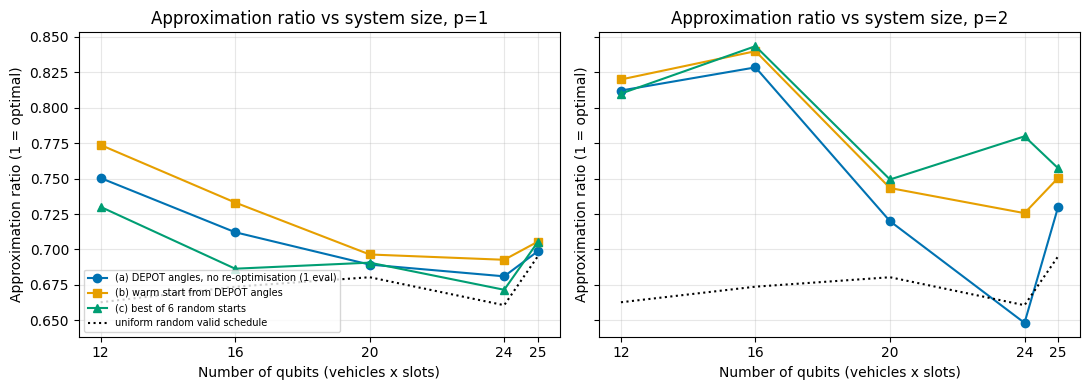

In [9]:
def sizes_for(p):
    return [transfer[(V, T, p)] for (V, T) in SIZES]

def save(fig, name):
    fig.tight_layout(); fig.savefig(f'{OUT}/{name}.png', dpi=140); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, p in zip(axes, (1, 2)):
    rs = sizes_for(p); q = [r['qubits'] for r in rs]
    ax.plot(q, [r['ar_direct'] for r in rs], 'o-', color=COL['transfer'], label='(a) DEPOT angles, no re-optimisation (1 eval)')
    ax.plot(q, [r['ar_warm'] for r in rs], 's-', color=COL['warm'], label='(b) warm start from DEPOT angles')
    ax.plot(q, [r['ar_random'] for r in rs], '^-', color=COL['random'], label=f'(c) best of {RESTARTS} random starts')
    ax.plot(q, [r['ar_uniform'] for r in rs], 'k:', label='uniform random valid schedule')
    ax.set_title(f'Approximation ratio vs system size, p={p}'); ax.set_xlabel('Number of qubits (vehicles x slots)')
    ax.set_xticks(q); ax.grid(alpha=.3)
for ax in axes: ax.set_ylabel('Approximation ratio (1 = optimal)')  # shared y, but label both panels
axes[0].legend(fontsize=7, loc='lower left')
save(fig, 'approx_ratio_vs_qubits')

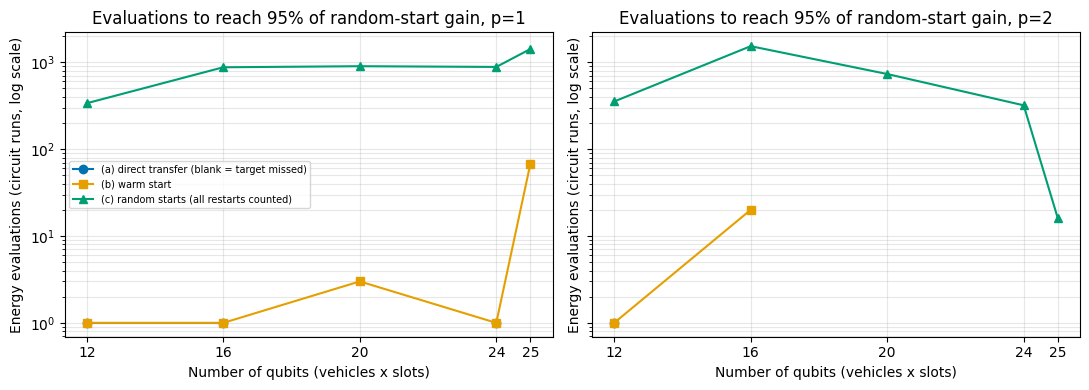

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, p in zip(axes, (1, 2)):
    rs = sizes_for(p); q = [r['qubits'] for r in rs]
    ev = lambda key: [np.nan if r[key] is None else r[key] for r in rs]
    ax.plot(q, ev('evals_direct'), 'o-', color=COL['transfer'], label='(a) direct transfer (blank = target missed)')
    ax.plot(q, ev('evals_warm'), 's-', color=COL['warm'], label='(b) warm start')
    ax.plot(q, ev('evals_random'), '^-', color=COL['random'], label='(c) random starts (all restarts counted)')
    ax.set_yscale('log'); ax.set_xticks(q); ax.grid(alpha=.3, which='both')
    ax.set_title(f'Evaluations to reach 95% of random-start gain, p={p}'); ax.set_xlabel('Number of qubits (vehicles x slots)')
for ax in axes: ax.set_ylabel('Energy evaluations (circuit runs, log scale)')  # shared y, but label both panels
axes[0].legend(fontsize=7)
save(fig, 'evaluations_vs_qubits')

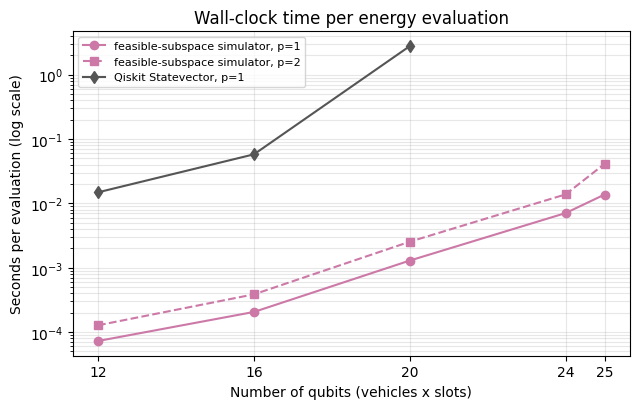

In [11]:
fig, ax = plt.subplots(figsize=(6.5, 4.2))
q_all = [scaling[(V, T, 1)]['qubits'] for V, T in SIZES]
for p, mk in ((1, 'o-'), (2, 's--')):
    ax.plot(q_all, [scaling[(V, T, p)]['sec_per_eval'] for V, T in SIZES], mk, color=COL['sim'], label=f'feasible-subspace simulator, p={p}')
ax.plot(list(qiskit_time), list(qiskit_time.values()), 'd-', color=COL['qiskit'], label='Qiskit Statevector, p=1')
ax.set_yscale('log'); ax.set_xticks(q_all); ax.grid(alpha=.3, which='both')
ax.set_title('Wall-clock time per energy evaluation'); ax.set_xlabel('Number of qubits (vehicles x slots)')
ax.set_ylabel('Seconds per evaluation (log scale)'); ax.legend(fontsize=8)
save(fig, 'time_per_eval_vs_qubits')

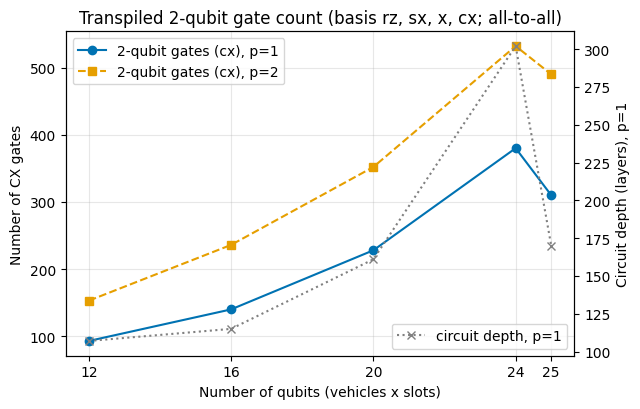

In [12]:
fig, ax = plt.subplots(figsize=(6.5, 4.2))
for p, mk in ((1, 'o-'), (2, 's--')):
    ax.plot(q_all, [circ_stats[(V, T, p)]['cx'] for V, T in SIZES], mk, color=COL['transfer'] if p == 1 else COL['warm'], label=f'2-qubit gates (cx), p={p}')
ax.set_xticks(q_all); ax.grid(alpha=.3)
ax.set_title('Transpiled 2-qubit gate count (basis rz, sx, x, cx; all-to-all)'); ax.set_xlabel('Number of qubits (vehicles x slots)')
ax.set_ylabel('Number of CX gates'); ax.legend()
ax2 = ax.twinx(); ax2.plot(q_all, [circ_stats[(V, T, 1)]['depth'] for V, T in SIZES], 'x:', color='grey', label='circuit depth, p=1')
ax2.set_ylabel('Circuit depth (layers), p=1'); ax2.legend(loc='lower right')
save(fig, 'cx_count_vs_qubits')

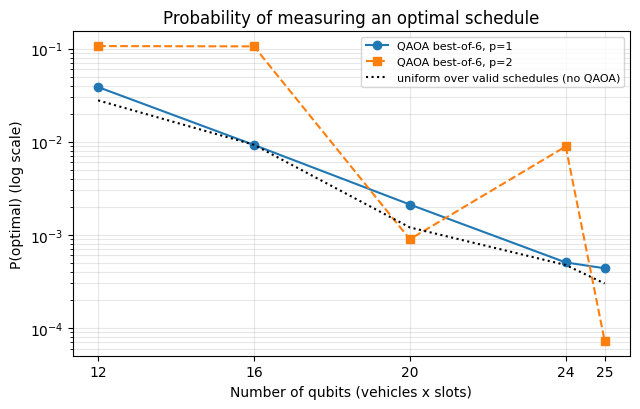

In [13]:
fig, ax = plt.subplots(figsize=(6.5, 4.2))
for p, mk in ((1, 'o-'), (2, 's--')):
    ax.plot(q_all, [scaling[(V, T, p)]['p_optimal'] for V, T in SIZES], mk, label=f'QAOA best-of-{RESTARTS}, p={p}')
ax.plot(q_all, [scaling[(V, T, 1)]['p_opt_uniform'] for V, T in SIZES], 'k:', label='uniform over valid schedules (no QAOA)')
ax.set_yscale('log'); ax.set_xticks(q_all); ax.grid(alpha=.3, which='both')
ax.set_title('Probability of measuring an optimal schedule'); ax.set_xlabel('Number of qubits (vehicles x slots)')
ax.set_ylabel('P(optimal) (log scale)'); ax.legend(fontsize=8)
save(fig, 'p_optimal_vs_qubits')

In [14]:
def clean(o):
    if isinstance(o, dict): return {str(k): clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [clean(v) for v in o]
    if isinstance(o, (np.floating, np.integer)): return o.item()
    return o
result = clean(dict(config=dict(weights=WEIGHTS, restarts=RESTARTS, maxiter=MAXITER, source_restarts=SOURCE_RESTARTS,
                                source_maxiter=SOURCE_MAXITER, basis=GATES), problems=rows, scaling=scaling,
                    circuit=circ_stats, qiskit_statevector_sec=qiskit_time, source_angles={p: source[p].tolist() for p in source},
                    transfer=transfer))
json.dump(result, open(f'{OUT}/scaling_results.json', 'w'), indent=1)
print(f'saved to results/03_scaling; notebook compute time {time.time()-T0:.0f} s')

saved to results/03_scaling; notebook compute time 321 s


## Findings & limitations

All numbers below come from this notebook's run (weights 0.5/0.3/0.2, XY mixer, Dicke start, COBYLA with 6 random restarts of at most 300 iterations; DEPOT source angles from 12 restarts of at most 500).

**Quality vs size (approximation ratio, best of 6 random starts; uniform-valid baseline in brackets).**

| size | qubits | p=1 | p=2 |
|---|---|---|---|
| 3x4 | 12 | 0.744 (0.663) | 0.810 (0.663) |
| 4x4 | 16 | 0.691 (0.674) | 0.844 (0.674) |
| 4x5 | 20 | 0.698 (0.680) | 0.746 (0.680) |
| 4x6 | 24 | 0.672 (0.661) | 0.779 (0.661) |
| 5x5 | 25 | 0.707 (0.695) | 0.757 (0.695) |

* At p=1, QAOA is only 0.01 to 0.02 above picking a valid schedule at random for every size beyond the depot (0.081 above it at 3x4). Depth p=2 adds a clear gain (+0.06 to +0.17 over uniform), but there is no clean downward trend with qubit count: 4x4 at p=2 beats the depot, 4x5 does not. Differences of a few hundredths between sizes are within what the capped optimiser and the different tariffs/demands can explain, so we do not claim a scaling law.
* The probability of measuring an exactly optimal schedule stays small and, beyond 16 qubits, is about the uniform value (e.g. 4x5 p=2: 0.0009 vs uniform 0.0012; 5x5 p=2: 0.0001 vs 0.0003). Lower mean energy did not translate into hitting the single best schedule. Only 3x4 (0.106 at p=2) and 4x4 (0.106 at p=2) are clearly better than chance (0.028 and 0.009).

**Cost of scaling.** Evaluations: the optimiser spent 1,531 to 1,800 evaluations over its restarts (1,800 is the cap). Time per evaluation with the feasible-subspace simulator grows from 0.07 ms (12 qubits, p=1) to 13.7 ms (25 qubits, p=1) and 41.2 ms at p=2 (5x5); these timings come from a shared CPU and vary run to run. Qiskit's `Statevector` takes 0.015 s, 0.058 s and 2.8 s per evaluation at 12, 16 and 20 qubits (p=1), against 0.07, 0.2 and 1.3 ms for the subspace simulator; it matches to 4e-15 on a random p=2 check. Transpiled 2-qubit (cx) gates, all-to-all, p=1 / p=2: 93/153 (3x4), 140/236 (4x4), 228/352 (4x5), 380/532 (4x6), 310/490 (5x5). Depth at p=1 goes from 107 to 302. The count is not a simple function of qubits: 5x5 (25 qubits) needs fewer cx than 4x6 (24 qubits), so slots per vehicle and number of vehicles matter separately.

**Parameter transfer (DEPOT angles).** The p=1 DEPOT angles were (beta, gamma) = (2.848, 7.354), AR 0.750, and p=2 angles (4.017, 1.608, 5.282, 2.739), AR 0.812.

| size | p | AR direct | AR warm | AR random | evals to 95% of random gain: direct / warm / random |
|---|---|---|---|---|---|
| 4x4 | 1 | 0.712 | 0.733 | 0.686 | 1 / 1 / 874 |
| 4x4 | 2 | 0.829 | 0.840 | 0.843 | missed / 20 / 1529 |
| 4x5 | 1 | 0.689 | 0.696 | 0.691 | missed / 3 / 899 |
| 4x5 | 2 | 0.720 | 0.743 | 0.749 | missed / missed / 731 |
| 4x6 | 1 | 0.681 | 0.693 | 0.672 | 1 / 1 / 882 |
| 4x6 | 2 | 0.648 | 0.726 | 0.780 | missed / missed / 319 |
| 5x5 | 1 | 0.699 | 0.706 | 0.705 | missed / 68 / 1418 |
| 5x5 | 2 | 0.730 | 0.751 | 0.757 | missed / missed / 16 |

* At p=1 the warm start matches or beats six random restarts on every size (e.g. 0.733 vs 0.686 at 4x4), and does so in 1 to 68 evaluations versus roughly 870 to 1,420. Direct transfer without any optimisation is better than random restarts on 4x4 and 4x6 (0.712 vs 0.686, 0.681 vs 0.672) and slightly worse on 4x5 and 5x5. This is where transfer pays off.
* At p=2 direct transfer never reaches the target on the larger sizes, even on 4x4 (which shares the depot's tariff), and falls well short of random starts on 4x6 (0.648 vs 0.780). A warm start recovers part of the gap (0.726 at 4x6) and reaches the target in 20 evaluations at 4x4, but misses it on 4x5, 4x6 and 5x5.
* Random-start numbers are themselves noisy: a capped optimiser from 6 starts sometimes lands below the transferred angles (3x4 p=1: 0.730 vs the 0.750 source angles), so "random" is a weak reference and "evals to 95%" is relative to it. Where the random result is poor (p=1), the target is easy and warm starts look very fast; at 5x5 p=2 the random runs reached their target after only 16 evaluations, which we read as a lucky early start rather than a general property.

**Limitations.** One seed per size; no repeated trials, so no error bars. Larger problems use equal demands of 2 while the depot uses (2, 1, 2), and the 5- and 6-slot tariffs are our own constructions, so size is confounded with problem shape. COBYLA budgets are capped, so approximation ratios are lower bounds on what each depth can reach. Gate counts are all-to-all and ignore hardware connectivity and noise (see the noisy-simulation study). The subspace simulator relies on the XY mixer keeping every state valid; it does not apply to the X mixer. Summary: p=1 QAOA hardly beats random valid sampling at 16+ qubits; p=2 helps; angles transfer well at p=1 and poorly at p=2.